## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [3]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Armon Haji

**Date:** 10/21/2026

In [12]:
# Your Phase 1 solution to the problem goes here.

# Q1

import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

In [13]:
token_freq[:10]

[('new', 1365),
 ('date', 1202),
 ('get', 1052),
 ('please', 1022),
 ('enron', 927),
 ('like', 923),
 ('2002', 869),
 ('would', 806),
 ('one', 798),
 ('message', 795)]

In [14]:
import matplotlib.pyplot as plt

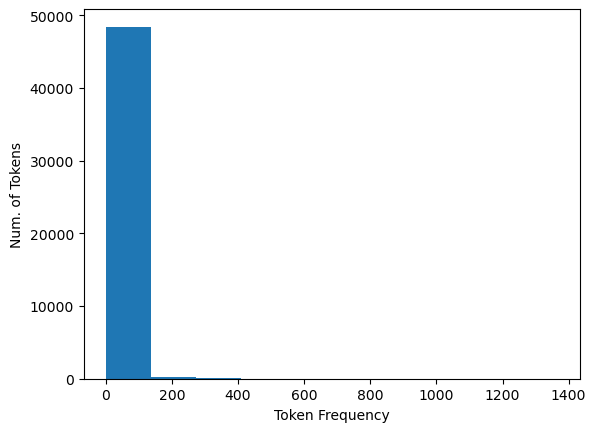

In [15]:
counts = []

for x in token_freq:
    counts.append(x[1])

plt.hist(counts)
plt.xlabel("Token Frequency")
plt.ylabel("Num. of Tokens")
plt.show()

In [16]:
## We can see clearly here that most of the tokens appear only a small number of times, while a few tokens appear very frequently. The 
## histogram is very right-skewed. This is due to the fact that there are a small number of words with very high frequencies.

In [17]:
# Q2

import pandas as pd

df = pd.read_parquet("data/Phishing_clean.parquet")
df.head()

,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("data/Phishing_clean.parquet")

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Training R2:", model.score(X_train, y_train))
print("Testing R2:", model.score(X_test, y_test))

coef = pd.Series(model.coef_, index=X.columns)
print(coef.abs().sort_values(ascending=False).head(10))

In [ ]:
## It appears the training R2 was about 0.77 and the testing R2 was about 0.67. What this means is 
## that the model did better on training data than testing data.  Words with bigger coefficients had 
## the strongest effect on the model's predictions.

In [ ]:
# Q3

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.scatter(X_pca[:,0], X_pca[:,1], c=y)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [ ]:
## There is separation between phishing and non-phishing emails. However, there's still a lot of 
## overlap. What this means is that the first two principal components capture some differences, 
## but they do not completely separate them.

In [ ]:
# Q4

from sklearn.decomposition import PCA

pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model2 = LinearRegression()
model2.fit(X_train_pca, y_train)

print("Training R2:", model2.score(X_train_pca, y_train))
print("Testing R2:", model2.score(X_test_pca, y_test))

In [ ]:
## The PCA model had about the same performance as the original regression. The training R2 was about
## 0.77 and the testing R2 was about 0.67. This means that the testing result was slightly better 
## with PCA.

In [ ]:
# Q5

## PCA is useful because it takes a large number of variables and combines them into fewer 
## components. It even does this while still keeping most of the important information. This can 
## make the regression easier to work with and can also reduce problems from variables that are very 
## similar to each other.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]